{'topic': '猫咪', 'poem': '《猫》\n轻灵似虎爪牙藏，昼伏夜行巡画堂。\n偶扑流萤翻砚瓦，时窥锦鲤立荷塘。\n窗台日暖慵梳毛，花径风清醉嗅香。\n莫道此君惟解睡，一声裂帛鼠惊惶。\n\n注：我的诗通过描绘猫的灵动与慵懒，展现其多面性。首联以“虎爪牙藏”暗喻猫的狩猎本性，颔联通过扑萤窥鱼展现其顽皮天性。颈联转写其慵懒享受阳光与花香，尾联则以“裂帛”喻猫捕鼠时的迅猛，形成强烈对比，突出猫的机警与能力。', 'ci_poem': '《清平乐·猫》\n绒团小玉，枝上扑飞絮。忽落花阴深处去，惊起一庭蝶羽。\n夜来轻踏书堆，墨痕爪印成梅。莫笑痴憨模样，须臾擒得鼠归。\n\n注：我的仿写创作思路是捕捉猫咪的灵动与顽皮。上阕用“绒团小玉”喻猫之可爱，通过扑絮、惊蝶的动态描写展现其活泼。下阕转写夜间的另一面，踏书留梅印的意象既写实又富有诗意，结句点出捕鼠本能，使猫咪形象立体丰满。全词语言凝练，画面感强，力求在古典词牌中注入现代生活气息。', 'content_type': '诗'}
{'topic': '猫咪', 'joke': '我问猫：“你为什么总把桌上的杯子推下去？”\n猫说：“我在测试重力。”\n我说：“可杯子已经碎三个了。”\n猫点点头：“嗯，实验数据很稳定。”', 'ci_poem': '《鹧鸪天·猫》\n软玉团成锦绣间，碧瞳如月照廊前。\n轻抬肉爪扑飞絮，暗伏花阴待小怜。\n穿书案，卧琴弦，偶然踏碎墨池烟。\n夜来忽作巡檐客，跃上青瓦嗅露眠。\n\n注：我的仿写创作思路是捕捉猫咪动静皆宜的灵性。上阕以“软玉”“碧瞳”写其静卧时的慵懒优雅，肉爪扑絮、花阴潜伏则暗藏机敏。下阕通过穿书案、卧琴弦、踏墨池等细节，展现猫与文人生活的诗意交融。结句夜巡青瓦、嗅露而眠，既呼应猫的夜行天性，又以露水意象赋予其超然灵气。', 'content_type': '笑话'}


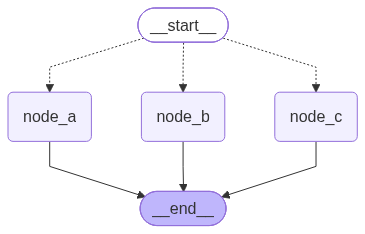

In [1]:
from typing import TypedDict,Literal,Sequence
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thingking":{
            "type":"disabled"
        }
    }
)

#1. 定义状态
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    ci_poem:str
    content_type: str

#2. 定义节点
def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([f"写一首关于{state['topic']}主题的诗"]).content
    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([f"写一个关于{state['topic']}主题的笑话"]).content
    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([f"写一首关于{state['topic']}主题的词"]).content
    return {
        "ci_poem": ci_poem
    }

def my_route(state: OverAllState) -> Sequence[Literal["node_a","node_b","node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a","node_c"]
    else:
        return ["node_b","node_c"]


#3. 构建图
builder = StateGraph(state_schema=OverAllState)
builder.add_node(node_a)
builder.add_node(node_b)
builder.add_node(node_c)

builder.add_conditional_edges(
    START,
    my_route,
    path_map={
        "node_a": "node_a",
        "node_b": "node_b",
        "node_c": "node_c",
    }
)
builder.add_edge("node_b",END)
builder.add_edge("node_a",END)
builder.add_edge("node_c",END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "猫咪","content_type":"诗"})
print(poem_res)

joke_res = graph.invoke({"topic": "猫咪","content_type":"笑话"})
print(joke_res)

from IPython.display import display
display(graph)
